In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Configure consistent plotting aesthetics
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

DATA_PATH = os.path.join("..", "data", "processed", "clean_movies.parquet")
df = pd.read_parquet(DATA_PATH)

print(f"Dataset shape: {df.shape[0]:,} movies x {df.shape[1]} columns")
print(f"Memory footprint: {df.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB\n")
print("Columns and dtypes:")
print(df.dtypes)

df.head(3)

Dataset shape: 51,616 movies x 20 columns
Memory footprint: 4223.86 MB

Columns and dtypes:
opus_id                    str
imdb_id                    str
tmdb_id                  int64
tmdb_title                 str
release_year               str
poster_url                 str
plot                       str
genres                     str
keywords                   str
original_language          str
runtime                float64
vote_average           float64
vote_count             float64
clean_plot                 str
clean_subtitles            str
plot_word_count          int64
subtitle_word_count      int64
has_valid_subtitles       bool
text_embedding             str
text_tfidf                 str
dtype: object


,opus_id,imdb_id,tmdb_id,tmdb_title,release_year,poster_url,plot,genres,keywords,original_language,runtime,vote_average,vote_count,clean_plot,clean_subtitles,plot_word_count,subtitle_word_count,has_valid_subtitles,text_embedding,text_tfidf
0,opus_7,tt0376076,69638,Pithamagan,2003,https://image.tmdb.org/t/p/w500/5arTF1o6FvdgJo...,A young orphan grows up in a graveyard and is ...,Action|Drama,undertaker|emotionless,ta,139.0,7.500,46.0,A young orphan grows up in a graveyard and is ...,Bodinayakkanur. CEMETERY Bodinayakkanur Cemete...,30,10841,True,"Title: Pithamagan (2003) | Genres: Action, Dra...",pithamagan action drama undertaker emotionless...
1,opus_9,tt0305357,9471,Charlie's Angels: Full Throttle,2003,https://image.tmdb.org/t/p/w500/n4cdJ0Wqxb7C0H...,The Angels are charged with finding a pair of ...,Action|Adventure|Comedy,martial arts|robbery|undercover agent|spy|secr...,en,106.0,5.481,3411.0,The Angels are charged with finding a pair of ...,© © © P @ rM! nder © P @ rM! nder M @ nkÖÖ © P...,39,6621,True,Title: Charlie's Angels: Full Throttle (2003) ...,charlie angel throttle action adventure comedy...
2,opus_23,tt0372166,208783,"Poor, Poor Pavel",2003,https://image.tmdb.org/t/p/w500/cl2MQqtrdzGrtr...,Lenfilm's most recent major production spins a...,Drama,,ru,103.0,3.900,9.0,Lenfilm's most recent major production spins a...,Halt! Guards! Follow me! Password! I need to s...,145,6255,True,"Title: Poor, Poor Pavel (2003) | Genres: Drama...",poor poor pavel drama lenfilm recent major pro...


In [3]:
# Check both true NaNs and empty strings ("") created during preprocessing normalization
missing_rows = []
total_rows = len(df)

for col in df.columns:
    na_count = df[col].isna().sum()
    empty_str_count = (
        df[col].fillna("").astype(str).str.strip().eq("").sum()
        if df[col].dtype == "object"
        else 0
    )
    total_missing = max(na_count, empty_str_count)
    missing_rows.append({
        "column": col,
        "missing_count": int(total_missing),
        "missing_pct": round((total_missing / total_rows) * 100, 2),
        "non_empty_count": int(total_rows - total_missing),
    })

missing_summary = pd.DataFrame(missing_rows).sort_values("missing_pct", ascending=False)
print("=== MISSING / EMPTY VALUE AUDIT ===")
display(missing_summary)

# Verify primary identifier uniqueness
print("\n=== DUPLICATE IDENTIFIER CHECK ===")
for id_col in ["opus_id", "imdb_id", "tmdb_id"]:
    if id_col in df.columns:
        dup_count = df[id_col].duplicated().sum()
        print(f"Duplicate {id_col}: {dup_count}")

# Check duplicate titles released in the same year (remakes vs. true collisions)
title_year_dups = df.duplicated(subset=["tmdb_title", "release_year"]).sum()
print(f"Duplicate (tmdb_title, release_year) pairs: {title_year_dups}")

=== MISSING / EMPTY VALUE AUDIT ===


,column,missing_count,missing_pct,non_empty_count
0,opus_id,0,0.0,51616
1,imdb_id,0,0.0,51616
2,tmdb_id,0,0.0,51616
3,tmdb_title,0,0.0,51616
4,release_year,0,0.0,51616
5,poster_url,0,0.0,51616
6,plot,0,0.0,51616
7,genres,0,0.0,51616
8,keywords,0,0.0,51616
9,original_language,2,0.0,51614



=== DUPLICATE IDENTIFIER CHECK ===
Duplicate opus_id: 0
Duplicate imdb_id: 0
Duplicate tmdb_id: 0
Duplicate (tmdb_title, release_year) pairs: 122


In [4]:
# Compute character lengths alongside existing word counts
df["plot_char_count"] = df["clean_plot"].str.len()
df["subtitle_char_count"] = df["clean_subtitles"].str.len()

numeric_cols = [
    "plot_word_count",
    "subtitle_word_count",
    "runtime",
    "vote_average",
    "vote_count",
]
available_numeric = [c for c in numeric_cols if c in df.columns]

print("=== SUMMARY STATISTICS ===")
display(df[available_numeric].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2))

# Flag unusually short or incomplete descriptions and subtitle files
empty_plots = (df["plot_word_count"] == 0).sum()
short_plots = ((df["plot_word_count"] > 0) & (df["plot_word_count"] < 10)).sum()
short_subs = (df["subtitle_word_count"] < 50).sum()
extreme_long_subs = (df["subtitle_word_count"] > 30_000).sum()

print("\n=== TEXT LENGTH ANOMALIES & QUALITY FLAGS ===")
print(f"Empty TMDB plots (0 words):             {empty_plots:,} ({empty_plots / total_rows:.2%})")
print(f"Unusually short plots (1–9 words):      {short_plots:,} ({short_plots / total_rows:.2%})")
print(f"Incomplete/short subtitles (<50 words): {short_subs:,} ({short_subs / total_rows:.2%})")
print(f"Extreme long subtitles (>30,000 words): {extreme_long_subs:,} ({extreme_long_subs / total_rows:.2%})")

print("\nSample movies with unusually short plots (1–9 words):")
display(
    df[(df["plot_word_count"] > 0) & (df["plot_word_count"] < 10)][
        ["imdb_id", "tmdb_title", "release_year", "plot_word_count", "clean_plot"]
    ].head(5)
)

=== SUMMARY STATISTICS ===


,plot_word_count,subtitle_word_count,runtime,vote_average,vote_count
count,51616.00,51616.00,51614.00,51614.00,51614.00
mean,50.67,6527.58,96.32,6.05,392.21
std,31.14,3414.20,31.14,1.30,1639.74
min,0.00,0.00,0.00,0.00,0.00
5%,15.00,1462.75,35.00,4.00,2.00
25%,27.00,4303.75,86.00,5.50,11.00
50%,43.00,6196.50,96.00,6.20,35.00
75%,67.00,8390.00,109.00,6.84,138.00
95%,115.00,12325.50,142.00,7.70,1657.35
max,191.00,57751.00,743.00,10.00,41913.00



=== TEXT LENGTH ANOMALIES & QUALITY FLAGS ===
Empty TMDB plots (0 words):             270 (0.52%)
Unusually short plots (1–9 words):      331 (0.64%)
Incomplete/short subtitles (<50 words): 92 (0.18%)
Extreme long subtitles (>30,000 words): 34 (0.07%)

Sample movies with unusually short plots (1–9 words):


,imdb_id,tmdb_title,release_year,plot_word_count,clean_plot
125,tt1520861,The Metropolis Case,2003,9,"A documentary about Fritz Langs ""Metropolis"" b..."
159,tt0386035,Sid Caesar Collection: Buried Treasures - The ...,2003,7,A collection of Ceasar's finest comedy moments.
164,tt0373704,Scratch,2003,9,A story of young love and early life choices.
326,tt0349678,Kerida,2003,4,Directed by Francis Posadas.
406,tt0768690,And in the Morning They Woke Up,2003,9,"Eight men, eight stories about the morning aft..."


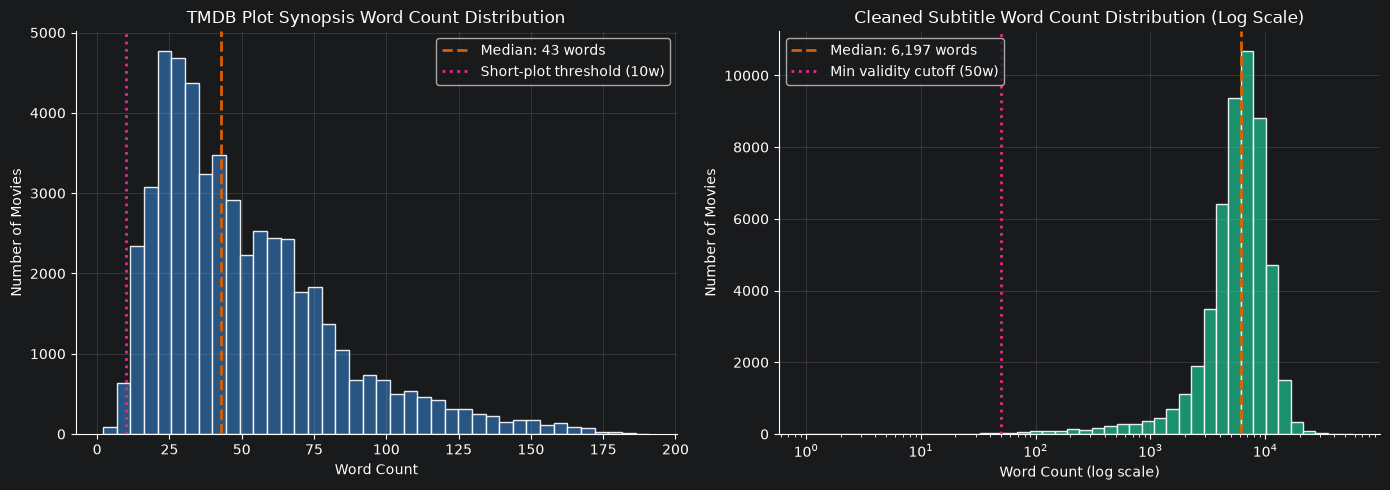

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left Panel: TMDB Plot Word Count Distribution
valid_plots = df.loc[df["plot_word_count"] > 0, "plot_word_count"]
axes[0].hist(valid_plots, bins=40, color="#2b5c8f", edgecolor="white", alpha=0.9)
axes[0].axvline(valid_plots.median(), color="#d95f02", linestyle="--", linewidth=2,
                label=f"Median: {valid_plots.median():.0f} words")
axes[0].axvline(10, color="#e7298a", linestyle=":", linewidth=2, label="Short-plot threshold (10w)")
axes[0].set_title("TMDB Plot Synopsis Word Count Distribution")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Number of Movies")
axes[0].legend()

# Right Panel: OPUS Subtitle Word Count Distribution (Log-spaced bins)
valid_subs = df.loc[df["subtitle_word_count"] > 0, "subtitle_word_count"]
log_bins = np.logspace(np.log10(1), np.log10(valid_subs.max()), 45)
axes[1].hist(valid_subs, bins=log_bins, color="#1b9e77", edgecolor="white", alpha=0.9)
axes[1].set_xscale("log")
axes[1].axvline(valid_subs.median(), color="#d95f02", linestyle="--", linewidth=2,
                label=f"Median: {valid_subs.median():,.0f} words")
axes[1].axvline(50, color="#e7298a", linestyle=":", linewidth=2, label="Min validity cutoff (50w)")
axes[1].set_title("Cleaned Subtitle Word Count Distribution (Log Scale)")
axes[1].set_xlabel("Word Count (log scale)")
axes[1].set_ylabel("Number of Movies")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Select ONLY the lightweight columns needed for genre analysis (avoids copying gigabytes of subtitle text)
genre_df = df.loc[df["genres"].str.strip() != "", ["genres", "subtitle_word_count"]].copy()
genre_df["genre_list"] = genre_df["genres"].str.split("|")
exploded_genres = genre_df[["genre_list", "subtitle_word_count"]].explode("genre_list")

top_genres = exploded_genres["genre_list"].value_counts().head(15)
median_words_by_genre = (
    exploded_genres[exploded_genres["genre_list"].isin(top_genres.index)]
    .groupby("genre_list")["subtitle_word_count"]
    .median()
    .loc[top_genres.index]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left Panel: Top 15 Genres by Movie Count
top_genres.sort_values().plot(kind="barh", ax=axes[0], color="#386cb0")
axes[0].set_title("Top 15 TMDB Genres by Movie Count")
axes[0].set_xlabel("Number of Movies")
axes[0].set_ylabel("")

# Right Panel: Median Subtitle Length per Genre
median_words_by_genre.sort_values().plot(kind="barh", ax=axes[1], color="#7570b3")
axes[1].set_title("Median Subtitle Word Count by Genre")
axes[1].set_xlabel("Median Words per Movie")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Print keyword coverage summary
has_keywords = (df["keywords"].str.strip() != "").sum()
print(f"Movies with at least 1 TMDB keyword: {has_keywords:,} ({has_keywords / len(df):.2%})")

In [ ]:
# Slice ONLY the lightweight columns needed for temporal & language analysis
cols_needed = ["release_year", "original_language"] if "original_language" in df.columns else ["release_year"]
meta_slice = df[cols_needed].copy()

meta_slice["year_num"] = pd.to_numeric(meta_slice["release_year"], errors="coerce")
valid_years = meta_slice.dropna(subset=["year_num"]).copy()
valid_years["decade"] = (valid_years["year_num"] // 10 * 10).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left Panel: Movies by Release Decade
decade_counts = valid_years[valid_years["decade"] >= 1920]["decade"].value_counts().sort_index()
decade_counts.plot(kind="bar", ax=axes[0], color="#2b5c8f", width=0.75)
axes[0].set_title("Dataset Coverage by Release Decade (1920s–2010s)")
axes[0].set_xlabel("Decade")
axes[0].set_ylabel("Number of Movies")
axes[0].tick_params(axis="x", rotation=45)

# Right Panel: Top 10 Original Production Languages
if "original_language" in meta_slice.columns:
    lang_counts = meta_slice["original_language"].replace("", "unknown").value_counts().head(10)
    lang_counts.sort_values().plot(kind="barh", ax=axes[1], color="#d95f02")
    axes[1].set_title("Top 10 Original Production Languages (TMDB)")
    axes[1].set_xlabel("Number of Movies")
    axes[1].set_ylabel("ISO Language Code")

plt.tight_layout()
plt.show()

# Quantify key bias indicators for the final report
total_rows = len(df)
post_2000 = (valid_years["year_num"] >= 2000).sum()
max_year = int(valid_years["year_num"].max())
en_orig = (meta_slice["original_language"] == "en").sum() if "original_language" in meta_slice.columns else 0

print("=== QUANTITATIVE BIAS & COVERAGE METRICS ===")
print(f"Latest release year in corpus:     {max_year} (OPUS v2018 cutoff)")
print(f"Movies released in or after 2000:  {post_2000:,} / {len(valid_years):,} ({post_2000 / len(valid_years):.2%})")
print(f"Original English-language films:   {en_orig:,} / {total_rows:,} ({en_orig / total_rows:.2%})")

## Dataset Bias, Coverage Limitations & Filtering Funnel

### 1. Corpus Acquisition & Filtering Funnel
* **446,612** raw English XML subtitle files in OPUS OpenSubtitles `v2018`.
* **140,044** unique IMDb IDs after deduplicating multiple community subtitle uploads per title (~68.6% reduction).
* **51,616** verified feature films after querying TMDB `/find` and excluding TV series episodes, shorts, and unlinked titles (~63.1% reduction).

### 2. Identified Coverage Limitations & Biases
1. **Temporal Cutoff (Pre-2019 Only):** Because the OPUS OpenSubtitles dump was compiled in 2018, the dataset contains no post-2018 theatrical releases.
2. **Digital-Era Recency Skew:** Community `.srt` subtitle creation expanded rapidly with DVD/digital distribution after 2000, heavily skewing the catalog toward 2000–2018 releases compared to classic cinema.
3. **Anglophone & Hollywood Dominance:** Filtering on the English subtitle archive (`en.zip`) results in a strong majority of English-language productions (`original_language == 'en'`), while non-English films are represented only if English fan/official subtitles were uploaded.
4. **Community Transcription & OCR Artifacts:** Fan-created subtitles occasionally introduce optical character recognition (OCR) typos (e.g., `I` vs. `l`), incomplete dialogue lines, or translated phrasing rather than original screenplay text.
5. **Metadata Sparsity on Obscure Titles:** Independent and older films exhibit higher rates of missing TMDB `keywords` and short `plot` synopses, making full subtitle dialogue essential for retrieval quality.

In [ ]:
SAMPLE_OUTPUT_PATH = os.path.join("..", "data", "processed", "sample_clean_movies.csv")

# Select key columns for inspection and teammate schema verification
handoff_cols = [
    "opus_id",
    "imdb_id",
    "tmdb_id",
    "tmdb_title",
    "release_year",
    "genres",
    "keywords",
    "plot_word_count",
    "subtitle_word_count",
    "has_valid_subtitles",
    "clean_plot",
    "text_embedding",
    "text_tfidf",
]
available_handoff_cols = [c for c in handoff_cols if c in df.columns]

sample_df = (
    df[df["has_valid_subtitles"] & (df["plot_word_count"] >= 15)]
    .sample(n=100, random_state=42)[available_handoff_cols]
)

sample_df.to_csv(SAMPLE_OUTPUT_PATH, index=False, sep=";", encoding="utf-8-sig")
print(f"Exported {len(sample_df)} sample movies to {SAMPLE_OUTPUT_PATH} (sep=';', utf-8-sig)")